# Customer Segmentation with K-Means

Unsupervised machine learning project that groups mall customers into segments based on their annual income and spending behavior, then describes each segment so it can be used for targeted marketing.

The dataset (200 customers) is the commonly used Mall Customers sample dataset ([Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python)). It is loaded directly from a public GitHub URL, so the notebook runs without any local file.

## library

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

## load data

In [2]:
url = "https://raw.githubusercontent.com/SteffiPeTaffy/machineLearningAZ/master/Machine%20Learning%20A-Z%20Template%20Folder/Part%204%20-%20Clustering/Section%2024%20-%20K-Means%20Clustering/Mall_Customers.csv"
df = pd.read_csv(url)
df = df.rename(columns={"Genre": "Gender", "Annual Income (k$)": "Income", "Spending Score (1-100)": "Spending"})
df.head()

,CustomerID,Gender,Age,Income,Spending
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.shape

(200, 5)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   CustomerID  200 non-null    int64
 1   Gender      200 non-null    str  
 2   Age         200 non-null    int64
 3   Income      200 non-null    int64
 4   Spending    200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


## check missing duplications

In [5]:
df.isnull().sum()

CustomerID    0
Gender        0
Age           0
Income        0
Spending      0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df = df.drop(columns=["CustomerID"])
df.describe()

,Age,Income,Spending
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


## data visual

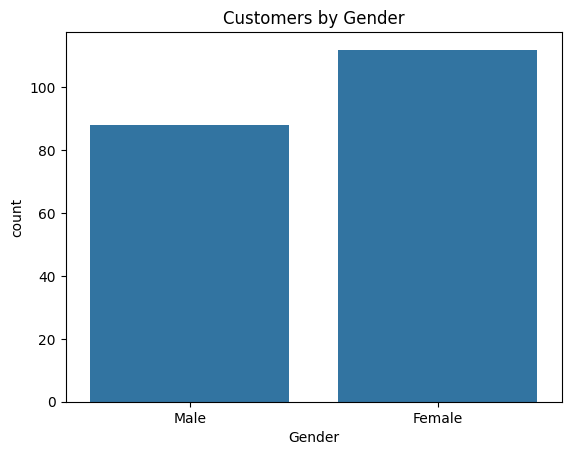

In [8]:
sns.countplot(x="Gender", data=df)
plt.title("Customers by Gender")
plt.show()

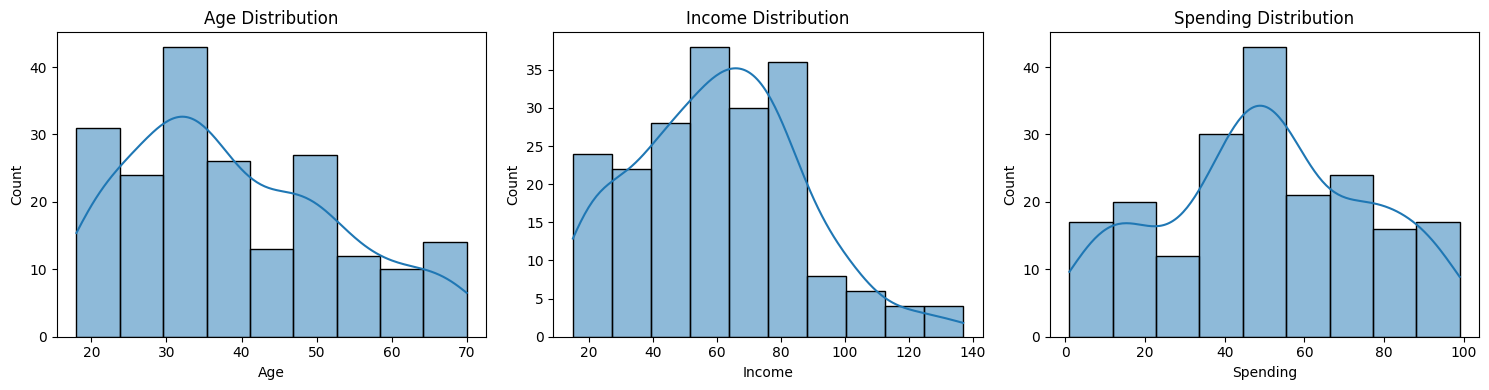

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Age", "Income", "Spending"]):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col + " Distribution")
plt.tight_layout()
plt.show()

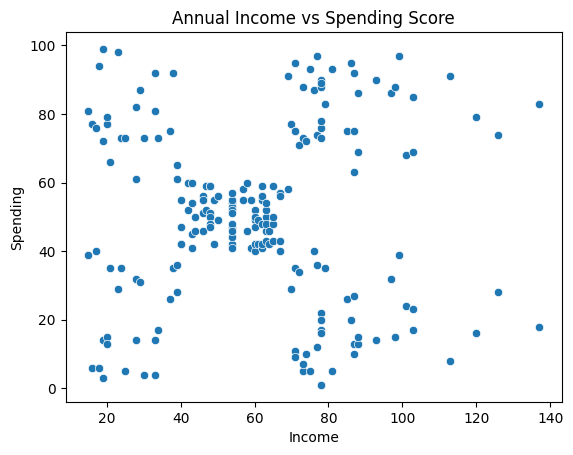

In [10]:
sns.scatterplot(x="Income", y="Spending", data=df)
plt.title("Annual Income vs Spending Score")
plt.show()

The scatter plot already shows visible groups. This is the kind of structure K-Means can find automatically.

## correlation analysis

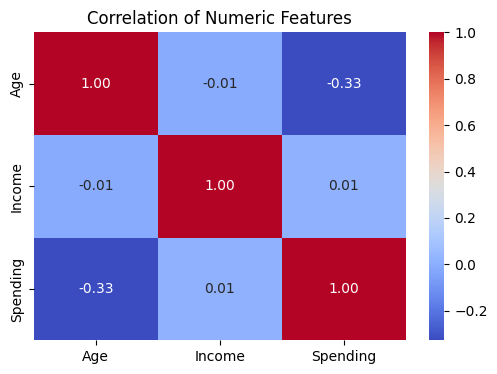

In [11]:
plt.figure(figsize=(6, 4))
sns.heatmap(df[["Age", "Income", "Spending"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation of Numeric Features")
plt.show()

Income and spending have almost no linear correlation, so a simple relationship cannot explain spending behavior. This is why clustering is useful here: the customer groups are defined by the combination of both.

## preprocessing

K-Means uses distances, so the features must be on the same scale. The clustering uses `Income` and `Spending`, which describe the customer's purchasing power and behavior. `Age` and `Gender` are not used for clustering and are kept to describe the segments afterwards.

In [12]:
features = ["Income", "Spending"]
scaler = StandardScaler()
X = scaler.fit_transform(df[features])

## choosing the number of clusters

K-Means needs the number of clusters in advance. Two methods are used together: the elbow method (where the inertia stops dropping sharply) and the silhouette score (how well separated the clusters are, higher is better).

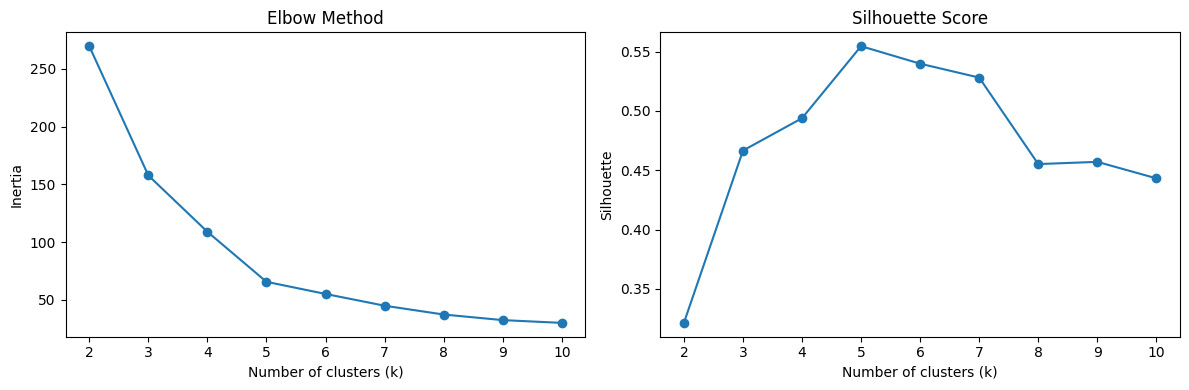

In [13]:
k_range = range(2, 11)
inertia = []
silhouette = []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_range, inertia, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[1].plot(k_range, silhouette, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

In [14]:
pd.DataFrame({"k": list(k_range), "Inertia": np.round(inertia, 1), "Silhouette": np.round(silhouette, 3)}).set_index("k")

,Inertia,Silhouette
k,,
2,269.7,0.321
3,157.7,0.467
4,108.9,0.494
5,65.6,0.555
6,55.1,0.540
7,44.9,0.528
8,37.2,0.455
9,32.4,0.457
10,30.0,0.443


In [15]:
best_k = list(k_range)[int(np.argmax(silhouette))]
best_k

5

## model

In [16]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
df["Cluster"] = kmeans.fit_predict(X)

print("Silhouette Score:", round(silhouette_score(X, df["Cluster"]), 3))
df["Cluster"].value_counts().sort_index()

Silhouette Score: 0.555


Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

## cluster visualization

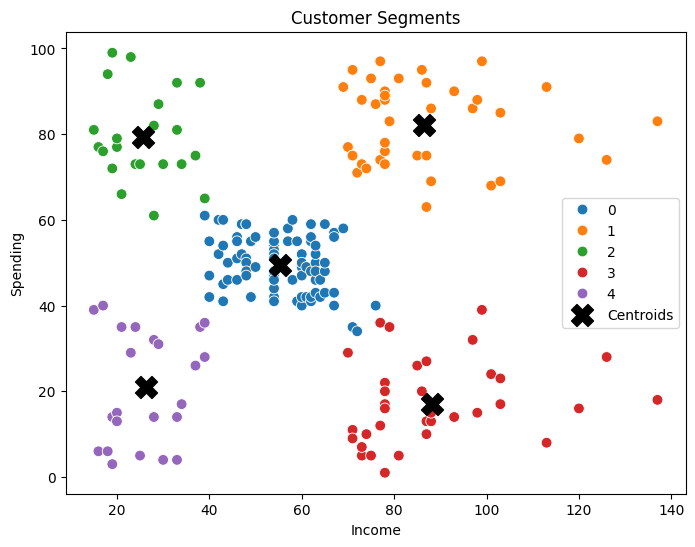

In [17]:
centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=features)

plt.figure(figsize=(8, 6))
sns.scatterplot(x="Income", y="Spending", hue="Cluster", data=df, palette="tab10", s=60)
plt.scatter(centers["Income"], centers["Spending"], c="black", marker="X", s=250, label="Centroids")
plt.title("Customer Segments")
plt.legend()
plt.show()

## cluster profiling

Each cluster is described by its average income, spending, and age, its size, and its gender mix. Segment names are assigned from the centroid values, so they stay correct even if the cluster numbers change when the notebook is run again.

In [18]:
def level(value, low, high):
    if value < low:
        return "Low"
    if value > high:
        return "High"
    return "Average"

profile = df.groupby("Cluster").agg(
    Customers=("Cluster", "size"),
    Avg_Income=("Income", "mean"),
    Avg_Spending=("Spending", "mean"),
    Avg_Age=("Age", "mean"),
    Female_Share=("Gender", lambda s: (s == "Female").mean())
).round(2)

profile["Segment"] = [
    level(row.Avg_Income, 40, 70) + " income, " + level(row.Avg_Spending, 40, 60).lower() + " spending"
    for row in profile.itertuples()
]
profile = profile.sort_values(["Avg_Income", "Avg_Spending"])
profile

,Customers,Avg_Income,Avg_Spending,Avg_Age,Female_Share,Segment
Cluster,,,,,,
2,22,25.73,79.36,25.27,0.59,"Low income, high spending"
4,23,26.30,20.91,45.22,0.61,"Low income, low spending"
0,81,55.30,49.52,42.72,0.59,"Average income, average spending"
1,39,86.54,82.13,32.69,0.54,"High income, high spending"
3,35,88.20,17.11,41.11,0.46,"High income, low spending"


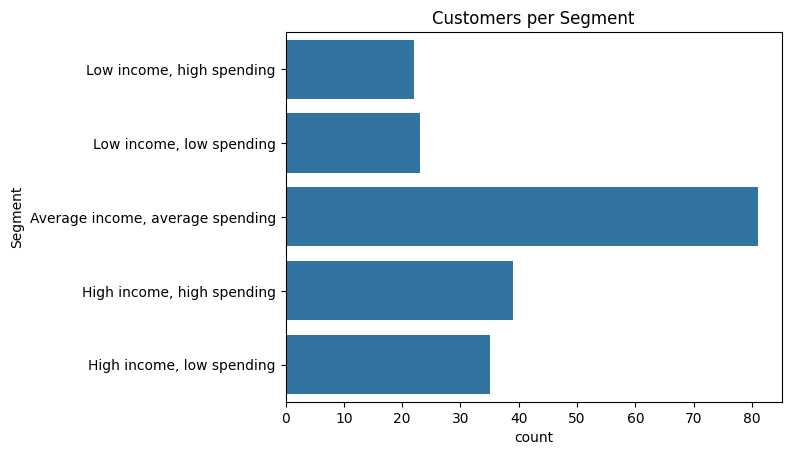

In [19]:
df["Segment"] = df["Cluster"].map(profile["Segment"])

sns.countplot(y="Segment", data=df, order=profile["Segment"])
plt.title("Customers per Segment")
plt.show()

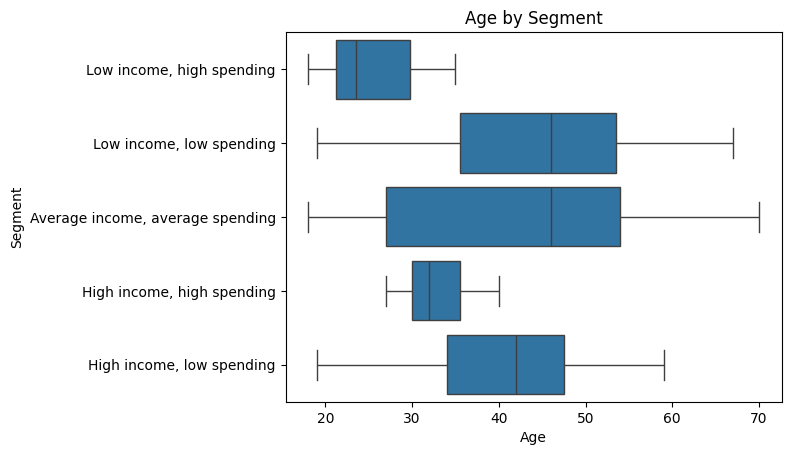

In [20]:
sns.boxplot(x="Age", y="Segment", data=df, order=profile["Segment"])
plt.title("Age by Segment")
plt.show()

## stability check

K-Means depends on a random starting point, so the result is checked by clustering again with 10 different random seeds and comparing each result with the final clusters using the adjusted Rand index (1.0 means identical grouping).

In [21]:
ari = []
for seed in range(10):
    labels = KMeans(n_clusters=best_k, n_init=10, random_state=seed).fit_predict(X)
    ari.append(adjusted_rand_score(df["Cluster"], labels))

print("Mean ARI:", round(np.mean(ari), 3))
print("Min ARI:", round(np.min(ari), 3))

Mean ARI: 1.0
Min ARI: 1.0


## data summary conclusion

- K-Means found 5 customer segments. Five clusters gave the highest silhouette score (0.555) and the elbow curve bends at the same point, so both methods agree.
- The result is stable: clustering again with 10 different random seeds gave exactly the same grouping each time (adjusted Rand index of 1.0).
- **Average income, average spending:** the largest segment with 81 customers (40.5%), average age about 43. A steady core group that responds to general promotions.
- **High income, high spending:** 39 customers (19.5%), average income about 87k$ and spending score 82, average age about 33. The most valuable customers, suitable for VIP and loyalty programs.
- **High income, low spending:** 35 customers (17.5%), average income about 88k$ but spending score only 17. They have the money but are not buying, so they are the biggest growth opportunity for premium offers and better targeting.
- **Low income, high spending:** 22 customers (11%), average income about 26k$ and spending score 79, with the youngest average age (about 25). They spend a lot relative to their income, so discounts and membership rewards fit them.
- **Low income, low spending:** 23 customers (11.5%), average income about 26k$ and spending score 21, average age about 45. The lowest priority for paid marketing.
- Gender is similar across segments (46% to 61% female), so it does not explain the groups. Age does: the two high-spending groups are the youngest.
- The marketing ideas above are suggestions based on the segment profiles and would need testing on real campaigns.
- Limits: the clustering uses only two features and 200 customers. This sample dataset is unusually clean, and real customer data is usually messier with less clear boundaries.
- Next steps: add `Age` to the clustering, compare with other methods such as hierarchical clustering and Gaussian mixture models, and apply RFM analysis (recency, frequency, monetary value) on real transaction data.